In [12]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import layers, Model

# Small sample corpus (lowercase and punctuation removed)
sentences = [
    "the cat sits on the mat",
    "the dog sits on the rug",
    "the cat eats fish",
    "the dog eats meat",
    "a cat likes fish",
    "a dog likes meat",
    "the cat likes the mat",
    "the dog likes the rug"
]

tokenized_sentences = [sentence.lower().split() for sentence in sentences]
vocabulary = sorted(set(word for sentence in tokenized_sentences for word in sentence))
word_to_id = {word: index for index, word in enumerate(vocabulary)}
id_to_word = {index: word for word, index in word_to_id.items()}

vocab_size = len(vocabulary)
print("Vocabulary:", vocabulary)
print("Vocabulary size:", vocab_size)
print("Word to ID:", word_to_id)

Vocabulary: ['a', 'cat', 'dog', 'eats', 'fish', 'likes', 'mat', 'meat', 'on', 'rug', 'sits', 'the']
Vocabulary size: 12
Word to ID: {'a': 0, 'cat': 1, 'dog': 2, 'eats': 3, 'fish': 4, 'likes': 5, 'mat': 6, 'meat': 7, 'on': 8, 'rug': 9, 'sits': 10, 'the': 11}


In [13]:
# Context window = 2 words on each side (up to 4 context words)
window_size = 2
contexts = []
targets = []

for sentence in tokenized_sentences:
    ids = [word_to_id[word] for word in sentence]
    for target_pos, target_id in enumerate(ids):
        left = ids[max(0, target_pos - window_size):target_pos]
        right = ids[target_pos + 1:target_pos + window_size + 1]
        context = left + right

        if context:  # Keep positions with at least one context word
            contexts.append(context)
            targets.append(target_id)

# Pad each context to a fixed length of 2 * window_size using -1.
# A mask below ignores padded values when averaging embeddings.
max_context_len = 2 * window_size
contexts_padded = np.full((len(contexts), max_context_len), -1, dtype=np.int32)
for i, context in enumerate(contexts):
    contexts_padded[i, :len(context)] = context

targets = np.array(targets, dtype=np.int32)

print("Number of training examples:", len(targets))
print("Context array shape:", contexts_padded.shape)
print("Target array shape:", targets.shape)

# Display a few examples
for i in range(min(8, len(targets))):
    context_words = [id_to_word[idx] for idx in contexts[i]]
    print(f"Context: {context_words}  -> Target: {id_to_word[targets[i]]}")

Number of training examples: 38
Context array shape: (38, 4)
Target array shape: (38,)
Context: ['cat', 'sits']  -> Target: the
Context: ['the', 'sits', 'on']  -> Target: cat
Context: ['the', 'cat', 'on', 'the']  -> Target: sits
Context: ['cat', 'sits', 'the', 'mat']  -> Target: on
Context: ['sits', 'on', 'mat']  -> Target: the
Context: ['on', 'the']  -> Target: mat
Context: ['dog', 'sits']  -> Target: the
Context: ['the', 'sits', 'on']  -> Target: dog


In [14]:
embedding_dim = 16

context_input = layers.Input(shape=(max_context_len,), dtype="int32", name="context_words")

# -1 is padding; replace it with 0 for safe embedding lookup, then mask padded positions.
safe_ids = layers.Lambda(lambda x: tf.maximum(x, 0), name="replace_padding")(context_input)
embedding_layer = layers.Embedding(
    input_dim=vocab_size,
    output_dim=embedding_dim,
    name="word_embedding"
)
embedded_words = embedding_layer(safe_ids)

valid_mask = layers.Lambda(lambda x: tf.cast(tf.not_equal(x, -1), tf.float32)[..., tf.newaxis],
                           name="context_mask")(context_input)
masked_embeddings = layers.Multiply()([embedded_words, valid_mask])
sum_embeddings = layers.Lambda(lambda x: tf.reduce_sum(x, axis=1))(masked_embeddings)
context_count = layers.Lambda(lambda x: tf.maximum(tf.reduce_sum(x, axis=1), 1.0))(valid_mask)
average_embedding = layers.Lambda(lambda items: items[0] / items[1], name="average_context_embedding")(
    [sum_embeddings, context_count]
)

output = layers.Dense(vocab_size, activation="softmax", name="target_word_probability")(average_embedding)
model = Model(context_input, output, name="CBOW_Model")

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.01),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

history = model.fit(
    contexts_padded,
    targets,
    epochs=150,
    batch_size=16,
    verbose=1
)

print("Training completed.")
print(f"Final training accuracy: {history.history['accuracy'][-1] * 100:.2f}%")

Model: "CBOW_Model"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ context_words       │ (None, 4)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ replace_padding     │ (None, 4)         │          0 │ context_words[0]… │
│ (Lambda)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ word_embedding      │ (None, 4, 16)     │        192 │ replace_padding[… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ context_mask        │ (None, 4, 1)      │          0 │ context_words[0]… │
│ (Lambda)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply_3          │ (None, 4, 16)     │          0 │ word_embedding[0… │
│ (Multiply)          │                   │            │ context_mask[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda_6 (Lambda)   │ (None, 16)        │          0 │ multiply_3[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda_7 (Lambda)   │ (None, 1)         │          0 │ context_mask[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ average_context_em… │ (None, 16)        │          0 │ lambda_6[0][0],   │
│ (Lambda)            │                   │            │ lambda_7[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ target_word_probab… │ (None, 12)        │        204 │ average_context_… │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 396 (1.55 KB)

 Trainable params: 396 (1.55 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/150
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.1579 - loss: 2.4866     
Epoch 2/150
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.3158 - loss: 2.4324
Epoch 3/150
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.2895 - loss: 2.3880
Epoch 4/150
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.2895 - loss: 2.3454
Epoch 5/150
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.3158 - loss: 2.2901
Epoch 6/150
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.3158 - loss: 2.2331
Epoch 7/150
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.3158 - loss: 2.1754
Epoch 8/150
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.3421 - loss: 2.1147
Epoch 9/150
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3421 - loss: 2.0470
Epoch 10/150
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.3684 - loss: 1.9791
Epoch 11/150
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.4211 - loss: 1.9208
Epoch 12/150
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.4474

In [15]:
def predict_target(context_words, top_k=5):
    # Convert context words to IDs and pad to the expected input length.
    ids = [word_to_id[word.lower()] for word in context_words if word.lower() in word_to_id]
    if not ids:
        print("No known context words were supplied.")
        return

    ids = ids[:max_context_len]
    padded = np.full((1, max_context_len), -1, dtype=np.int32)
    padded[0, :len(ids)] = ids

    probabilities = model.predict(padded, verbose=0)[0]
    best_ids = np.argsort(probabilities)[::-1][:top_k]

    print("Context words:", context_words)
    print("Predicted target words:")
    for word_id in best_ids:
        print(f"  {id_to_word[int(word_id)]:<12} probability = {probabilities[word_id]:.4f}")

# Example: ask the model to predict a word from surrounding context
predict_target(["cat", "on", "mat"], top_k=5)

# Show a few predictions on examples from the training set
print("\nSample training predictions:")
for i in range(min(5, len(targets))):
    context_words = [id_to_word[idx] for idx in contexts[i]]
    true_word = id_to_word[int(targets[i])]
    predicted_id = int(np.argmax(model.predict(contexts_padded[i:i+1], verbose=0)[0]))
    print(f"Context: {context_words} | Actual: {true_word} | Predicted: {id_to_word[predicted_id]}")

Context words: ['cat', 'on', 'mat']
Predicted target words:
  the          probability = 0.9322
  on           probability = 0.0363
  likes        probability = 0.0106
  fish         probability = 0.0089
  a            probability = 0.0067

Sample training predictions:
Context: ['cat', 'sits'] | Actual: the | Predicted: the
Context: ['the', 'sits', 'on'] | Actual: cat | Predicted: dog
Context: ['the', 'cat', 'on', 'the'] | Actual: sits | Predicted: sits
Context: ['cat', 'sits', 'the', 'mat'] | Actual: on | Predicted: on
Context: ['sits', 'on', 'mat'] | Actual: the | Predicted: the


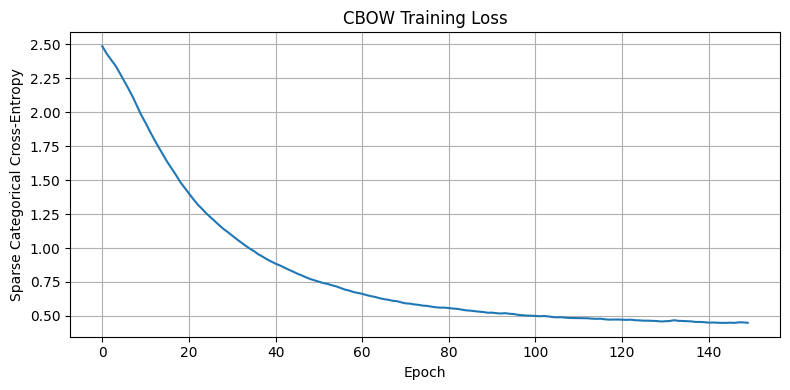

In [16]:
plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"])
plt.title("CBOW Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Sparse Categorical Cross-Entropy")
plt.grid(True)
plt.tight_layout()
plt.show()